# 모듈과 타입힌트

**이 노트북에서 할 일**

1. 6절 클래스 `OrderLine`의 정의를 파일 `order_tools.py`에 저장하고, `import`로 불러와 씁니다.
2. 이 노트북과 모듈에 붙은 이름을 출력해, 6절 자료형에 나온 `__main__`의 뜻을 확인합니다.
3. 타입힌트를 적은 함수에 문자열 단가를 넣어 보고, 넣기 전에 정수로 바꿔 고칩니다.

**준비물** — API 키 불필요. 모듈 파일은 노트북이 임시 폴더에 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

1~6절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고릅니다.
이전 커널의 변수는 쓰지 않으므로 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

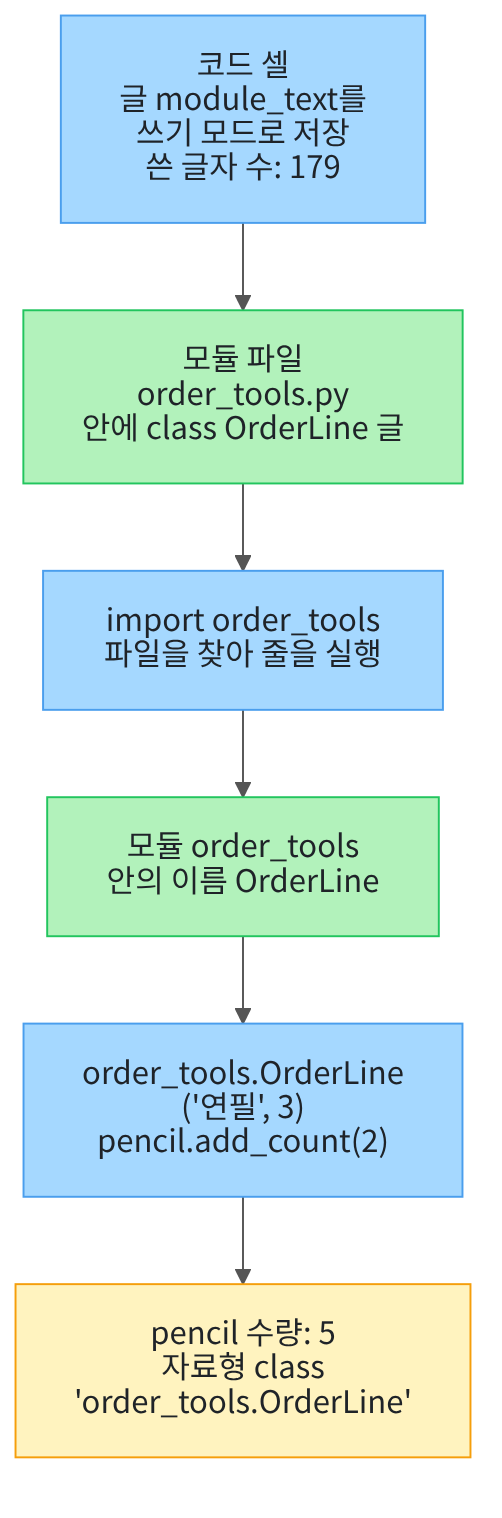

위에서 아래로 읽습니다. 파란 상자는 우리가 적은 코드, 초록 상자는 파일과 모듈, 노란 상자는 출력입니다.

글로 저장한 파일 order_tools.py를 import 줄이 모듈로 불러옵니다.
모듈 이름 뒤에 점을 찍어 클래스를 쓰자, 자료형 앞에 모듈 이름 order_tools가 붙었습니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 이 노트북은 모듈 파일을 만들므로, 5절처럼 파일을 둘 빈 폴더를 먼저 준비합니다.

준비 셀은 운영체제의 임시 폴더 안에 새 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
그래서 뒤 셀의 파일 이름 `"order_tools.py"`는 이 새 폴더 안의 파일을 가리킵니다.

첫 두 줄의 `import`는 5절 준비 셀과 같습니다. 1절과 5절에서 뜻을 미룬 이 줄은 3번 소제목에서 배웁니다.

In [1]:
# 모듈 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch02-07-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 클래스 정의를 모듈 파일에 저장하기

6절에서 정의한 클래스 `OrderLine`은 6절 노트북 안에만 있습니다. 새 노트북에서 쓰려면 정의를 다시 적어야 합니다.
정의를 파일에 저장해 두면, 필요한 곳에서 불러 쓸 수 있습니다.

Ch 1 3절에서 모듈(module)은 import 뒤에 적어 불러오는 기능 묶음 한 단위라고 했습니다.
우리가 직접 만드는 모듈은 함수나 클래스 정의를 담은 `.py` 파일 하나입니다. 공구함 서랍에 공구를 넣어 두고 필요할 때 꺼내 쓰는 것과 같습니다.
파일 이름 order_tools.py에서 `.py`를 뺀 order_tools가 모듈 이름이 됩니다.

이 셀은 6절 정의 셀과 같은 클래스 정의를 여러 줄 글로 적어 파일에 저장합니다. 글 안의 정의는 아직 실행되지 않습니다.
저장은 5절처럼 쓰기 모드 `"w"`와 메서드 `write()`로 합니다.

실행 전에 예상합니다. 저장한 뒤 현재 작업 폴더에는 파일 order_tools.py 하나가 보일 것입니다.

In [2]:
# 6절 클래스 OrderLine의 정의를 글로 적어 파일 order_tools.py에 저장합니다
module_text = """class OrderLine:
    def __init__(self, name, count):
        self.name = name
        self.count = count

    def add_count(self, extra):
        self.count = self.count + extra
"""
# 5절처럼 쓰기 모드로 열어 글을 저장합니다
with open("order_tools.py", "w", encoding="utf-8") as file:
    written_count = file.write(module_text)
file_names = os.listdir()
print("쓴 글자 수:", written_count)
print("현재 작업 폴더의 파일:", file_names)

쓴 글자 수: 179
현재 작업 폴더의 파일: ['order_tools.py']


**결과 읽기** — 쓴 글자 수는 `179`이고, 현재 작업 폴더의 파일은 `['order_tools.py']`로 예상과 같습니다.
파일 안의 글은 Python 코드지만, 저장한 방법은 5절의 주문 두 줄과 같습니다.
편집기 VS Code에서 새 파일 order_tools.py를 만들어 같은 글을 적어도 모듈 파일이 됩니다. 이 방법은 이번에 실행하지 않았습니다.

## 3. import 문으로 모듈 불러오기

예약어 `import` 뒤에 모듈 이름을 적은 줄을 import 문(import statement)이라고 합니다.
이 줄은 모듈 파일을 찾아 불러와서, 그 안의 이름을 쓸 수 있게 합니다.
파일은 Python이 정해 둔 폴더 목록에서 찾습니다. 노트북에서는 현재 작업 폴더도 이 목록에 들어 있습니다.

처음 불러올 때는 파일의 줄이 위에서부터 실행됩니다. 이때 글로 저장한 클래스 정의가 실행되어, 모듈 안에 클래스 `OrderLine`이 만들어집니다.
불러온 뒤에는 모듈 이름 뒤에 점을 찍고 안의 이름을 적습니다. 6절에서 속성을 읽을 때 쓴 점과 같습니다.

1절 준비 셀의 `import platform`, 5절과 이 노트북 준비 셀의 `import os`도 같은 import 문입니다.
모듈 os와 tempfile은 Python을 설치할 때 함께 들어 있는 모듈입니다. 이런 모듈 모음을 표준 라이브러리(standard library)라고 합니다.
준비 셀의 `os.chdir()`는 모듈 os 안의 함수 chdir를 부른 줄입니다.

실행 전에 예상합니다. 6절처럼 수량 3에 2를 더해 pencil 수량은 5일 것입니다. 6절 자료형 앞에 붙었던 `__main__`은 이번에도 나올까요?

In [3]:
# 모듈 order_tools를 불러와, 모듈 이름 뒤에 점을 찍고 클래스를 씁니다
import order_tools

pencil = order_tools.OrderLine("연필", 3)
pencil.add_count(2)
pencil_type = type(pencil)
print("pencil 수량:", pencil.count)
print("pencil의 자료형:", pencil_type)

pencil 수량: 5
pencil의 자료형: <class 'order_tools.OrderLine'>


**결과 읽기** — pencil 수량은 `5`로 예상과 같습니다. 자료형은 `<class 'order_tools.OrderLine'>`입니다.

6절 노트북에서 같은 모양의 클래스로 만든 인스턴스의 자료형은 <class '__main__.OrderLine'>였습니다.
이번에는 점 앞이 모듈 이름 order_tools로 바뀌었습니다. 점 앞의 이름이 무엇인지 다음 셀에서 확인합니다.

## 4. 모듈 이름 읽기

모듈마다 이름이 붙어 있습니다. 모듈 이름 뒤에 점과 `__name__`을 적어 그 이름을 읽습니다.
6절 `__init__`처럼 앞뒤의 밑줄 두 개는 Python이 정해 둔 특별한 이름이라는 표시입니다.

셀에 모듈 이름 없이 `__name__`만 적으면, 지금 실행 중인 코드의 이름을 읽습니다.
준비 셀에서 불러온 모듈 os의 이름과 자료형도 함께 봅니다.

실행 전에 예상합니다. 모듈 order_tools의 이름은 order_tools, 모듈 os의 이름은 os일 것입니다. 이 노트북의 이름은 무엇일까요?

In [4]:
# 이 노트북, 우리가 만든 모듈, 준비 셀의 os 모듈에 붙은 이름을 봅니다
notebook_name = __name__
tools_name = order_tools.__name__
os_name = os.__name__
print("이 노트북의 이름:", notebook_name)
print("order_tools의 이름:", tools_name)
print("os의 이름:", os_name)
# 우리가 만든 모듈과 표준 라이브러리 모듈의 자료형을 비교합니다
print("order_tools의 자료형:", type(order_tools))
print("os의 자료형:", type(os))

이 노트북의 이름: __main__
order_tools의 이름: order_tools
os의 이름: os
order_tools의 자료형: <class 'module'>
os의 자료형: <class 'module'>


**결과 읽기** — 이 노트북의 이름은 `__main__`입니다. 모듈 order_tools의 이름은 `order_tools`, 모듈 os의 이름은 `os`입니다.
두 모듈의 자료형은 모두 `<class 'module'>`입니다.

직접 실행하는 코드에는 Python이 이름 `__main__`을 붙입니다. 노트북 셀에서 정의한 이름은 모두 이 `__main__`에 속합니다.
그래서 6절 노트북 셀에서 정의한 클래스의 자료형에는 __main__이 붙었습니다.
우리가 만든 order_tools도 표준 라이브러리 os와 자료형이 같은 모듈입니다.

## 5. from import 문으로 이름 하나만 가져오기

import 문을 `from 모듈 import 이름` 순서로 적으면, 모듈에서 고른 이름만 노트북으로 가져옵니다.
가져온 이름은 모듈 이름과 점 없이 바로 씁니다. Ch 1 2절 노트북의 `from pathlib import Path`도 이 모양이었습니다.

이번에는 클래스 이름 `OrderLine`만 가져와 노트 주문 줄을 만듭니다. 6절 값 바꿔 보기처럼 수량에 2를 더합니다.

실행 전에 예상합니다. note 수량은 2에 2를 더한 4이고, 자료형은 pencil과 같을 것입니다.

In [5]:
# 모듈에서 클래스 이름 OrderLine만 가져와, 모듈 이름 없이 씁니다
from order_tools import OrderLine

note = OrderLine("노트", 2)
note.add_count(2)
note_type = type(note)
print("note 수량:", note.count)
print("note의 자료형:", note_type)

note 수량: 4
note의 자료형: <class 'order_tools.OrderLine'>


**결과 읽기** — note 수량은 `4`, 자료형은 `<class 'order_tools.OrderLine'>`으로 예상과 같습니다.
두 방법으로 가져온 클래스는 모두 모듈 order_tools 안의 OrderLine입니다. 가져오는 줄에 따라, 부를 때 적는 이름만 달라집니다.

## 6. 정의 줄에 타입힌트 적기

모듈로 나눈 정의는 쓰는 곳과 파일이 다릅니다. 부르는 사람은 정의를 열어 보지 않고도 무엇을 넣을지 알아야 합니다.

타입힌트(type hint)는 매개변수와 반환값에 기대하는 자료형을 정의 줄에 적은 표시입니다.
저금통 몸통에 동전 그림 스티커를 붙여 두면, 넣는 사람은 동전을 넣으면 된다는 것을 압니다.
아래 셀은 4절 함수 `calculate_line_total()`의 정의 줄에 타입힌트를 적어 다시 정의합니다. 본문은 4절과 같습니다.

매개변수 이름 뒤에 콜론과 자료형을 적습니다. 표시 `unit_price: int`는 단가에 정수를 넣기로 한다는 뜻입니다.
기본값이 있는 매개변수는 `quantity: int = 1`처럼 자료형 뒤에 기본값을 적습니다.
괄호 뒤 화살표 `->` 다음의 `int`는 이 함수가 정수를 반환한다는 표시입니다.

실행 전에 예상합니다. 4절처럼 정의 셀이라 출력은 없을 것입니다.

In [6]:
# 4절 함수의 정의 줄에 매개변수와 반환값의 자료형을 적어 다시 정의합니다
def calculate_line_total(unit_price: int, quantity: int = 1) -> int:
    line_total = unit_price * quantity
    return line_total

**결과 읽기** — 예상대로 출력이 없습니다. 정의 셀은 함수 이름, 본문, 기본값과 함께 타입힌트도 기억해 둡니다.

4절과 같은 단가 39000과 수량 2를 넣어 함수를 부릅니다. 반환값의 자료형도 함께 출력합니다.

실행 전에 예상합니다. 4절처럼 78000이 나오고, 자료형은 정수일 것입니다.

In [7]:
# 4절과 같은 단가와 수량으로 부르고, 반환값의 자료형을 봅니다
unit_price = 39000
quantity = 2
line_total = calculate_line_total(unit_price, quantity)
total_type = type(line_total)
print("주문 줄 금액:", line_total)
print("금액의 자료형:", total_type)

주문 줄 금액: 78000
금액의 자료형: <class 'int'>


**결과 읽기** — 주문 줄 금액은 `78000`, 금액의 자료형은 `<class 'int'>`로 예상과 같습니다.
4절의 타입힌트 없는 함수도 같은 인자로 78000을 반환했습니다. 타입힌트를 적어도 계산 방법은 바뀌지 않습니다.

## 7. 값 바꿔 보기 — 수량 하나만 바꾸기

함수를 다시 정의하지 않고 수량만 2에서 3으로 바꿔 부릅니다. 단가 39000은 그대로 둡니다.

실행 전에 예상합니다. 39000원짜리 3개이므로 금액은 117000이고, 자료형은 정수일 것입니다.

In [8]:
# 단가는 그대로 두고 수량만 3으로 바꿔 같은 함수를 부릅니다
new_quantity = 3
new_total = calculate_line_total(unit_price, new_quantity)
print("수량 2일 때 금액:", line_total)
print("수량 3일 때 금액:", new_total)
print("금액의 자료형:", type(new_total))

수량 2일 때 금액: 78000
수량 3일 때 금액: 117000
금액의 자료형: <class 'int'>


**결과 읽기** — 수량 3일 때 금액은 `117000`으로 예상과 같습니다. 수량 2일 때 금액 `78000`도 남아 있습니다.
두 금액의 차이 39000은 단가와 같습니다. 1절에서 수량 3으로 계산한 117000.0과 같은 금액이고, 이번에는 정수입니다.

## 8. Before — 파일에서 읽은 단가를 그대로 넣기

주문 파일에서 「무선 키보드,39000」 한 줄을 읽었다고 합니다. 5절처럼 `split(",")`으로 나누면 상품 이름과 단가를 꺼낼 수 있습니다.
5절 함수 `parse_order()`는 나눈 수량을 `int()`로 바꿨습니다. 이번 셀은 이 줄을 빠뜨리고, 나눈 단가를 그대로 함수에 넣습니다.

함수의 정의 줄에는 `unit_price: int`라고 적혀 있습니다.
실행 전에 예상해 봅니다. 문자열 단가를 넣으면 오류가 날까요, 금액 78000이 나올까요?

In [9]:
# 5절처럼 글 한 줄을 쉼표로 나눠 상품 이름과 단가를 꺼냅니다
price_line = "무선 키보드,39000"
product_name, unit_price_text = price_line.split(",")
# 타입힌트가 int인 매개변수에 나눈 단가를 그대로 넣습니다
wrong_total = calculate_line_total(unit_price_text, quantity)
expected_total = 78000
is_expected = wrong_total == expected_total
print("상품 이름:", product_name)
print("주문 줄 금액:", wrong_total)
print("금액의 자료형:", type(wrong_total))
print("78000과 같은가:", is_expected)

상품 이름: 무선 키보드
주문 줄 금액: 3900039000
금액의 자료형: <class 'str'>
78000과 같은가: False


**결과 읽기** — 오류 메시지 없이 실행되었습니다. 주문 줄 금액은 `3900039000`, 금액의 자료형은 `<class 'str'>`입니다. 78000과 같은가는 `False`입니다.

나눈 단가가 문자열 '39000'이라서, 문자열에 수량 2를 곱해 글자를 두 번 이어 붙였습니다.
1절 Before에서 문자열 "2"에 3을 곱해 222가 된 것과 같은 계산입니다.
정의 줄에 int라고 적었지만, 문자열 단가는 막히지 않았습니다. 실행이 멈추지 않아도 결과는 틀릴 수 있습니다.

### 원리 더 알아보기 — 타입힌트가 저장된 곳

정의 줄에 적은 타입힌트는 함수의 속성 `__annotations__`에 딕셔너리로 저장됩니다.
이 속성은 앞으로 쓰지 않으므로 지금은 출력만 읽습니다.

In [10]:
# 원리 더 알아보기: 함수에 저장된 타입힌트를 읽습니다
saved_hints = calculate_line_total.__annotations__
print("저장된 타입힌트:", saved_hints)

저장된 타입힌트: {'unit_price': <class 'int'>, 'quantity': <class 'int'>, 'return': <class 'int'>}


**결과 읽기** — 저장된 타입힌트는 `{'unit_price': <class 'int'>, 'quantity': <class 'int'>, 'return': <class 'int'>}`입니다.
키 'return'은 화살표 뒤에 적은 반환값의 자료형입니다.

타입힌트는 함수에 기록되어 있었지만, 호출할 때 넣은 값과 비교되지 않았습니다.
Python 자습서는 이 기록이 함수의 다른 부분에 영향을 주지 않는다고 설명합니다.

## 9. After — int()로 바꾼 뒤 넣기

Before 셀과 달라진 곳은 함수에 넣기 전에 `int()`로 단가를 정수로 바꾸는 줄 하나입니다. 함수 정의, 단가 글자, 수량 2는 그대로입니다.
타입힌트는 무엇을 넣을지 알려 줄 뿐입니다. 값을 알맞은 자료형으로 바꾸는 일은 우리가 적은 코드가 합니다.

실행 전에 예상합니다. 금액은 78000, 자료형은 정수이고, 78000과 같은가는 True일 것입니다.

In [11]:
# 함수에 넣기 전에 int()로 문자열 단가를 정수로 바꿉니다
unit_price_number = int(unit_price_text)
line_total = calculate_line_total(unit_price_number, quantity)
is_expected = line_total == expected_total
print("바꾼 단가의 자료형:", type(unit_price_number))
print("주문 줄 금액:", line_total)
print("금액의 자료형:", type(line_total))
print("78000과 같은가:", is_expected)
# 금액이 78000이 아니면 이 줄에서 멈춥니다
assert line_total == expected_total

바꾼 단가의 자료형: <class 'int'>
주문 줄 금액: 78000
금액의 자료형: <class 'int'>
78000과 같은가: True


**결과 읽기** — 바꾼 단가의 자료형은 `<class 'int'>`입니다. 주문 줄 금액은 `78000`, 78000과 같은가는 `True`입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

같은 함수에 같은 단가 글자로 실행한 Before에서는 3900039000이었습니다. 달라진 곳은 `int()`로 바꾸는 줄 하나입니다.

정수로 바꿀 수 없는 글자(예: 「삼만구천」)를 넣는 장면은 이번에 실행하지 않았습니다. 타입힌트를 읽어 맞지 않는 곳을 찾는 도구도 이번에 실행하지 않았습니다.

## 정리

- 모듈은 정의를 담은 `.py` 파일 하나입니다. 6절 클래스를 order_tools.py에 저장하고, import 문으로 불러와 pencil 수량 5를 얻었습니다.
- 모듈마다 이름이 있습니다. 직접 실행하는 이 노트북의 이름은 `__main__`이라서, 6절 노트북에서 정의한 클래스의 자료형에 붙었습니다.
- 타입힌트는 기대하는 자료형을 적은 표시이고, 값을 검사하지 않습니다. 문자열 단가를 넣자 3900039000, `int()`로 바꾼 뒤 넣자 78000이었습니다.

다음 절에서는 함수가 기대한 값을 반환하는지 pytest로 확인합니다.